In [ ]:

# Import pandas to inspect the exported coverage dataset.
import pandas as pd

# Load the CSV file (upload it to Colab first if it is not already there).
from google.colab import files
uploaded = files.upload()

# Read the uploaded CSV and display its structure.
file_name = next(iter(uploaded))
coverage_df = pd.read_csv(file_name)

print("Dataset shape:", coverage_df.shape)
print("\nColumn names:", coverage_df.columns.tolist())
print("\nFirst five rows:")
display(coverage_df.head())

print("\nMissing values:")
print(coverage_df.isna().sum())


Saving Ghana_MODIS_NDVI_Annual_Coverage_2000_2024.csv to Ghana_MODIS_NDVI_Annual_Coverage_2000_2024.csv
Dataset shape: (25, 4)

Column names: ['system:index', 'coverage', 'year', '.geo']

First five rows:


,system:index,coverage,year,.geo
0,0,0.290254,2000,"{""type"":""MultiPoint"",""coordinates"":[]}"
1,1,0.329524,2001,"{""type"":""MultiPoint"",""coordinates"":[]}"
2,2,0.319434,2002,"{""type"":""MultiPoint"",""coordinates"":[]}"
3,3,0.386418,2003,"{""type"":""MultiPoint"",""coordinates"":[]}"
4,4,0.290296,2004,"{""type"":""MultiPoint"",""coordinates"":[]}"



Missing values:
system:index    0
coverage        0
year            0
.geo            0
dtype: int64


Step 2 — Validate the years and coverage values

In [ ]:

# Validate year coverage, duplicate records, and coverage ranges.

print("Year range:", coverage_df["year"].min(), "to", coverage_df["year"].max())
print("Number of unique years:", coverage_df["year"].nunique())
print("Duplicate year records:", coverage_df["year"].duplicated().sum())

expected_years = set(range(2000, 2025))
actual_years = set(coverage_df["year"].astype(int))
print("Missing years:", sorted(expected_years - actual_years))

print("\nCoverage summary:")
print(coverage_df["coverage"].describe())

print("\nCoverage outside the valid 0–1 range:",
      ((coverage_df["coverage"] < 0) |
       (coverage_df["coverage"] > 1)).sum())

print("\nAnnual coverage percentages:")
display(
    coverage_df[["year", "coverage"]]
    .sort_values("year")
    .assign(coverage_percent=lambda df: (df["coverage"] * 100).round(2))
    [["year", "coverage_percent"]]
    .reset_index(drop=True)
)


Year range: 2000 to 2024
Number of unique years: 25
Duplicate year records: 0
Missing years: []

Coverage summary:
count    25.000000
mean      0.336019
std       0.030927
min       0.274816
25%       0.308528
50%       0.345269
75%       0.353292
max       0.393123
Name: coverage, dtype: float64

Coverage outside the valid 0–1 range: 0

Annual coverage percentages:


,year,coverage_percent
0,2000,29.03
1,2001,32.95
2,2002,31.94
3,2003,38.64
4,2004,29.03
5,2005,30.46
6,2006,34.52
7,2007,34.61
8,2008,34.61
9,2009,35.14


### Annual NDVI Coverage Validation (2000–2024)

The exported annual MODIS NDVI coverage dataset contained 25 records representing every year from 2000 through 2024. Validation identified no duplicate years, missing years, missing values, or coverage values outside the valid range of 0–1.

Mean annual good-quality coverage was 33.60%, with a minimum of 27.48% in 2016 and a maximum of 39.31% in 2013.

These coverage values represent the fraction of Ghana's boundary with qualifying observations under the current MODIS SummaryQA filtering and annual averaging method. They do not represent the proportion of land covered by vegetation.

**Methodological limitation:** The relatively low spatial coverage may limit the representativeness of annual NDVI estimates. The 2000 coverage value was also obtained using an earlier average-mask calculation, whereas the subsequent annual values came from the batch coverage script. This difference must be documented when interpreting the dataset.

The coverage table has passed basic structural validation. Further assessment of observation quality and temporal compositing is required before estimating or interpreting long-term vegetation trends.


Next step — Test seasonal coverage for 2000

In [ ]:

 // Test good-quality MODIS NDVI coverage for Ghana, January–March 2000

var ghana = ee.FeatureCollection('FAO/GAUL/2015/level0')
  .filter(ee.Filter.eq('ADM0_NAME', 'Ghana'))
  .geometry();

var modis2000 = ee.ImageCollection('MODIS/061/MOD13Q1')
  .filterDate('2000-01-01', '2000-04-01')
  .select(['NDVI', 'SummaryQA']);

var goodQuality2000 = modis2000.map(function(image) {
  var good = image.select('SummaryQA').eq(0);
  return image.select('NDVI')
    .multiply(0.0001)
    .updateMask(good)
    .rename('NDVI')
    .copyProperties(image, ['system:time_start']);
});

// Estimate the mean fraction of Ghana with good-quality observations
// across the January–March image collection.
var seasonalMask = goodQuality2000
  .count()
  .gt(0)
  .rename('covered');

var seasonalCoverage = seasonalMask.reduceRegion({
  reducer: ee.Reducer.mean(),
  geometry: ghana,
  scale: 1000,
  maxPixels: 1e10,
  tileScale: 4
});

print('Season:', 'January–March 2000');
print('Images available:', modis2000.size());
print('Seasonal spatial coverage:', seasonalCoverage);


SyntaxError: invalid character '–' (U+2013) (299719823.py, line 1)

In [2]:

# Description: Upload and combine the five annual NDVI CSV exports.

import pandas as pd
from google.colab import files
from io import BytesIO

uploaded = files.upload()

expected_files = [
    "Ghana_Annual_NDVI_2000_2004.csv",
    "Ghana_Annual_NDVI_2005_2009.csv",
    "Ghana_Annual_NDVI_2010_2014.csv",
    "Ghana_Annual_NDVI_2015_2019.csv",
    "Ghana_Annual_NDVI_2020_2024.csv"
]

missing_files = [name for name in expected_files if name not in uploaded]

if missing_files:
    print("Missing files:", missing_files)
else:
    ndvi_df = pd.concat(
        [pd.read_csv(BytesIO(uploaded[name])) for name in expected_files],
        ignore_index=True
    )

    ndvi_df["year"] = pd.to_numeric(ndvi_df["year"], errors="coerce")
    ndvi_df = ndvi_df.sort_values("year").reset_index(drop=True)

    print("Combined dataset shape:", ndvi_df.shape)
    print("\nColumn names:")
    print(ndvi_df.columns.tolist())
    print("\nFirst five rows:")
    display(ndvi_df.head())
    print("\nLast five rows:")
    display(ndvi_df.tail())


Saving Ghana_Annual_NDVI_2000_2004.csv to Ghana_Annual_NDVI_2000_2004 (1).csv
Saving Ghana_Annual_NDVI_2005_2009.csv to Ghana_Annual_NDVI_2005_2009.csv
Saving Ghana_Annual_NDVI_2010_2014.csv to Ghana_Annual_NDVI_2010_2014 (1).csv
Saving Ghana_Annual_NDVI_2015_2019.csv to Ghana_Annual_NDVI_2015_2019.csv
Saving Ghana_Annual_NDVI_2020_2024.csv to Ghana_Annual_NDVI_2020_2024 (1).csv
Missing files: ['Ghana_Annual_NDVI_2000_2004.csv', 'Ghana_Annual_NDVI_2010_2014.csv', 'Ghana_Annual_NDVI_2020_2024.csv']


In [3]:

# Description: Combine all five annual NDVI exports and validate year coverage.

import pandas as pd
import glob
import os

# Find the five annual batch files, including renamed duplicates.
all_files = glob.glob("/content/Ghana_Annual_NDVI_*.csv")

batch_ranges = [
    (2000, 2004),
    (2005, 2009),
    (2010, 2014),
    (2015, 2019),
    (2020, 2024)
]

frames = []

for first_year, last_year in batch_ranges:
    matches = [
        f for f in all_files
        if f"_{first_year}_{last_year}.csv" in f
    ]

    if not matches:
        raise FileNotFoundError(
            f"Missing CSV for {first_year}–{last_year}"
        )

    # Use the first matching file for this batch.
    file_path = matches[0]
    batch = pd.read_csv(file_path)
    print(f"{first_year}–{last_year}: {os.path.basename(file_path)}")
    frames.append(batch)

ndvi_df = pd.concat(frames, ignore_index=True)

ndvi_df["year"] = pd.to_numeric(ndvi_df["year"], errors="coerce")
ndvi_df = ndvi_df.sort_values("year").reset_index(drop=True)

print("\nCombined dataset shape:", ndvi_df.shape)
print("Columns:", ndvi_df.columns.tolist())
print("Year range:", ndvi_df["year"].min(), "to", ndvi_df["year"].max())
print("Number of unique years:", ndvi_df["year"].nunique())
print("Duplicate year records:", ndvi_df["year"].duplicated().sum())
print("\nFirst five rows:")
display(ndvi_df.head())
print("\nLast five rows:")
display(ndvi_df.tail())


2000–2004: Ghana_Annual_NDVI_2000_2004.csv
2005–2009: Ghana_Annual_NDVI_2005_2009.csv
2010–2014: Ghana_Annual_NDVI_2010_2014.csv
2015–2019: Ghana_Annual_NDVI_2015_2019.csv
2020–2024: Ghana_Annual_NDVI_2020_2024.csv

Combined dataset shape: (25, 6)
Columns: ['system:index', 'annual_mean_ndvi', 'image_count', 'valid_spatial_fraction', 'year', '.geo']
Year range: 2000.0 to 2024.0
Number of unique years: 25
Duplicate year records: 0

First five rows:


,system:index,annual_mean_ndvi,image_count,valid_spatial_fraction,year,.geo
0,0,0.553957,20,1.0,2000.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
1,1,0.513885,23,1.0,2001.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
2,2,0.573142,23,1.0,2002.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
3,3,0.566151,23,1.0,2003.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
4,4,0.585937,23,1.0,2004.0,"{""type"":""MultiPoint"",""coordinates"":[]}"



Last five rows:


,system:index,annual_mean_ndvi,image_count,valid_spatial_fraction,year,.geo
20,0,0.558906,23,1.0,2020.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
21,1,0.568968,23,1.0,2021.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
22,2,0.563057,23,1.0,2022.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
23,3,0.542199,23,1.0,2023.0,"{""type"":""MultiPoint"",""coordinates"":[]}"
24,4,0.523007,23,1.0,2024.0,"{""type"":""MultiPoint"",""coordinates"":[]}"


In [4]:

# Description: Validate annual NDVI values, missing data, and coverage.

import numpy as np
import pandas as pd

# Check the main research variables.
required_cols = [
    "year",
    "annual_mean_ndvi",
    "image_count",
    "valid_spatial_fraction"
]

print("Missing values:")
display(ndvi_df[required_cols].isna().sum().to_frame("missing_count"))

print("\nNDVI descriptive statistics:")
display(ndvi_df["annual_mean_ndvi"].describe().to_frame())

print("\nImage count by year:")
display(ndvi_df[["year", "image_count"]].to_string(index=False))

print("\nCoverage fraction summary:")
display(ndvi_df["valid_spatial_fraction"].describe().to_frame())

# Flag values needing investigation; do not modify the data.
print("\nQuality flags:")
print("NDVI outside -1 to 1:",
      ((ndvi_df["annual_mean_ndvi"] < -1) |
       (ndvi_df["annual_mean_ndvi"] > 1)).sum())

print("Coverage outside 0 to 1:",
      ((ndvi_df["valid_spatial_fraction"] < 0) |
       (ndvi_df["valid_spatial_fraction"] > 1)).sum())

print("Years with fewer than 20 images:",
      ndvi_df.loc[ndvi_df["image_count"] < 20, "year"].tolist())

print("Years with coverage below 1:",
      ndvi_df.loc[
          ndvi_df["valid_spatial_fraction"] < 1,
          ["year", "valid_spatial_fraction"]
      ].to_dict("records"))


Missing values:


,missing_count
year,0
annual_mean_ndvi,0
image_count,0
valid_spatial_fraction,0



NDVI descriptive statistics:


,annual_mean_ndvi
count,25.000000
mean,0.552888
std,0.021221
min,0.509502
25%,0.542199
50%,0.558906
75%,0.568533
max,0.585937



Image count by year:


'  year  image_count\n2000.0           20\n2001.0           23\n2002.0           23\n2003.0           23\n2004.0           23\n2005.0           23\n2006.0           23\n2007.0           23\n2008.0           23\n2009.0           23\n2010.0           23\n2011.0           23\n2012.0           23\n2013.0           23\n2014.0           23\n2015.0           23\n2016.0           23\n2017.0           23\n2018.0           23\n2019.0           23\n2020.0           23\n2021.0           23\n2022.0           23\n2023.0           23\n2024.0           23'


Coverage fraction summary:


,valid_spatial_fraction
count,25.0
mean,1.0
std,0.0
min,1.0
25%,1.0
50%,1.0
75%,1.0
max,1.0



Quality flags:
NDVI outside -1 to 1: 0
Coverage outside 0 to 1: 0
Years with fewer than 20 images: []
Years with coverage below 1: []


Study period: 2000 – 2024
Number of annual observations: 25
Mean annual NDVI: 0.5529
Trend slope: -0.000570 NDVI units/year
Change per decade: -0.0057 NDVI units
R-squared: 0.0391
P-value: 0.3431
Statistical result: No statistically significant linear trend at p < 0.05.


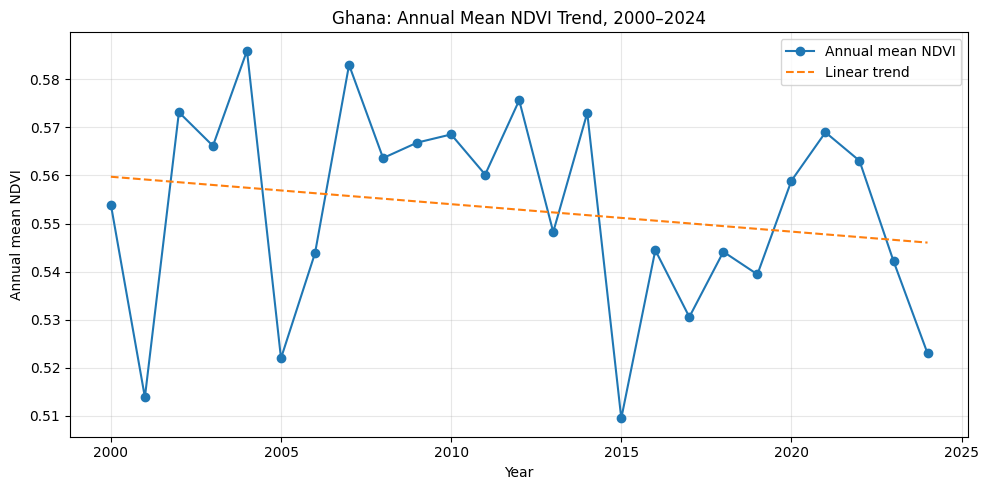

In [5]:

# Description: Analyze and plot Ghana's annual NDVI trend, 2000–2024.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Prepare annual observations
trend_df = ndvi_df[["year", "annual_mean_ndvi"]].copy()
trend_df = trend_df.dropna().sort_values("year")

# Estimate the linear trend
result = linregress(
    trend_df["year"],
    trend_df["annual_mean_ndvi"]
)

print("Study period:", int(trend_df["year"].min()), "–",
      int(trend_df["year"].max()))
print("Number of annual observations:", len(trend_df))
print(f"Mean annual NDVI: {trend_df['annual_mean_ndvi'].mean():.4f}")
print(f"Trend slope: {result.slope:.6f} NDVI units/year")
print(f"Change per decade: {result.slope * 10:.4f} NDVI units")
print(f"R-squared: {result.rvalue**2:.4f}")
print(f"P-value: {result.pvalue:.4f}")

if result.pvalue < 0.05:
    print("Statistical result: Significant linear trend at p < 0.05.")
else:
    print("Statistical result: No statistically significant linear trend at p < 0.05.")

# Plot observed annual NDVI and fitted linear trend
plt.figure(figsize=(10, 5))
plt.plot(
    trend_df["year"],
    trend_df["annual_mean_ndvi"],
    marker="o",
    label="Annual mean NDVI"
)
plt.plot(
    trend_df["year"],
    result.intercept + result.slope * trend_df["year"],
    linestyle="--",
    label="Linear trend"
)
plt.xlabel("Year")
plt.ylabel("Annual mean NDVI")
plt.title("Ghana: Annual Mean NDVI Trend, 2000–2024")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [6]:

# Description: Save annual NDVI trend statistics and validated annual data.

trend_summary = pd.DataFrame([{
    "study_start_year": int(trend_df["year"].min()),
    "study_end_year": int(trend_df["year"].max()),
    "n_years": len(trend_df),
    "mean_annual_ndvi": trend_df["annual_mean_ndvi"].mean(),
    "slope_per_year": result.slope,
    "change_per_decade": result.slope * 10,
    "r_squared": result.rvalue ** 2,
    "p_value": result.pvalue,
    "significant_at_0_05": result.pvalue < 0.05
}])

trend_summary.to_csv(
    "ghana_annual_ndvi_trend_summary_2000_2024.csv",
    index=False
)

ndvi_df.to_csv(
    "ghana_annual_ndvi_2000_2024.csv",
    index=False
)

print("Saved:")
print("- ghana_annual_ndvi_trend_summary_2000_2024.csv")
print("- ghana_annual_ndvi_2000_2024.csv")


Saved:
- ghana_annual_ndvi_trend_summary_2000_2024.csv
- ghana_annual_ndvi_2000_2024.csv


In [7]:

# Description: Load the annual rainfall estimates and inspect their structure.

from google.colab import files
import pandas as pd
from io import BytesIO

uploaded_rainfall = files.upload()

rainfall_filename = next(
    name for name in uploaded_rainfall
    if name.endswith(".csv")
)

rainfall_df = pd.read_csv(
    BytesIO(uploaded_rainfall[rainfall_filename])
)

print("Loaded file:", rainfall_filename)
print("Dataset shape:", rainfall_df.shape)
print("\nColumn names:")
print(rainfall_df.columns.tolist())

print("\nFirst five rows:")
display(rainfall_df.head())

print("\nData types:")
print(rainfall_df.dtypes)


Saving ghana_annual_rainfall_estimates_2000_2024.csv to ghana_annual_rainfall_estimates_2000_2024.csv
Loaded file: ghana_annual_rainfall_estimates_2000_2024.csv
Dataset shape: (25, 2)

Column names:
['year', 'annual_rainfall_mm']

First five rows:


,year,annual_rainfall_mm
0,2000,1126.608681
1,2001,1043.306209
2,2002,1231.959347
3,2003,1271.682950
4,2004,1164.307682



Data types:
year                    int64
annual_rainfall_mm    float64
dtype: object


Step 2 — Merge rainfall and NDVI, then calculate correlation

In [8]:

# Description: Merge annual rainfall and NDVI and test their association.

from scipy.stats import pearsonr, spearmanr
import pandas as pd

# Prepare consistent year columns and retain required variables.
rainfall_clean = rainfall_df[["year", "annual_rainfall_mm"]].copy()
ndvi_clean = ndvi_df[["year", "annual_mean_ndvi"]].copy()

rainfall_clean["year"] = pd.to_numeric(
    rainfall_clean["year"], errors="coerce"
).astype("Int64")

ndvi_clean["year"] = pd.to_numeric(
    ndvi_clean["year"], errors="coerce"
).astype("Int64")

# Merge on year.
rainfall_ndvi = pd.merge(
    rainfall_clean,
    ndvi_clean,
    on="year",
    how="inner",
    validate="one_to_one"
).sort_values("year").reset_index(drop=True)

print("Merged dataset shape:", rainfall_ndvi.shape)
print("Year range:",
      int(rainfall_ndvi["year"].min()), "to",
      int(rainfall_ndvi["year"].max()))
print("Missing values:")
display(rainfall_ndvi.isna().sum().to_frame("missing_count"))

print("\nFirst five merged records:")
display(rainfall_ndvi.head())

# Calculate correlations using the annual values.
pearson_r, pearson_p = pearsonr(
    rainfall_ndvi["annual_rainfall_mm"],
    rainfall_ndvi["annual_mean_ndvi"]
)

spearman_rho, spearman_p = spearmanr(
    rainfall_ndvi["annual_rainfall_mm"],
    rainfall_ndvi["annual_mean_ndvi"]
)

print("\nRainfall–NDVI association (n =", len(rainfall_ndvi), ")")
print(f"Pearson correlation: r = {pearson_r:.4f}, p = {pearson_p:.4f}")
print(f"Spearman correlation: rho = {spearman_rho:.4f}, p = {spearman_p:.4f}")


Merged dataset shape: (25, 3)
Year range: 2000 to 2024
Missing values:


,missing_count
year,0
annual_rainfall_mm,0
annual_mean_ndvi,0



First five merged records:


,year,annual_rainfall_mm,annual_mean_ndvi
0,2000,1126.608681,0.553957
1,2001,1043.306209,0.513885
2,2002,1231.959347,0.573142
3,2003,1271.682950,0.566151
4,2004,1164.307682,0.585937



Rainfall–NDVI association (n = 25 )
Pearson correlation: r = 0.5003, p = 0.0109
Spearman correlation: rho = 0.4577, p = 0.0214


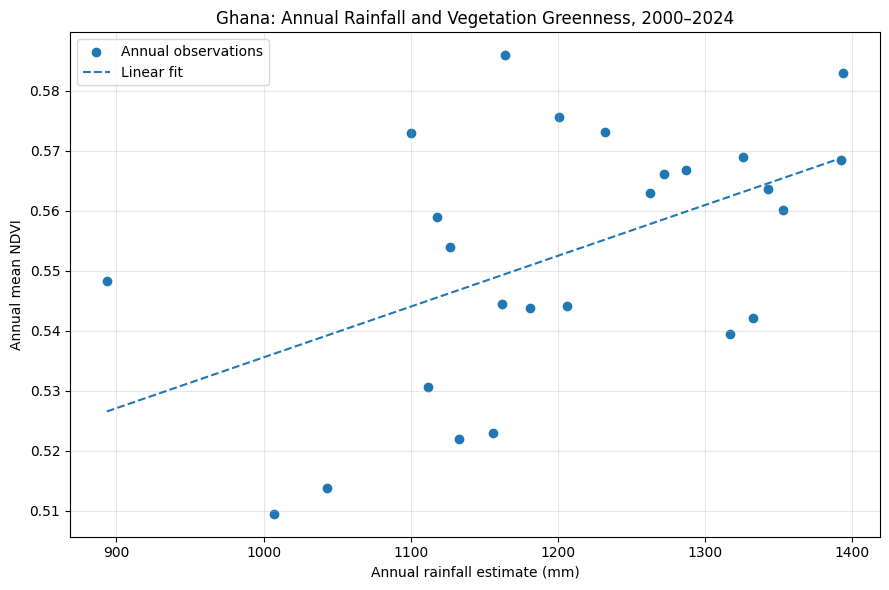

Saved merged dataset, correlation summary, and 300-dpi figure.


In [9]:

# Description: Plot rainfall–NDVI association and save merged research outputs.

import matplotlib.pyplot as plt
from scipy.stats import linregress

x = rainfall_ndvi["annual_rainfall_mm"]
y = rainfall_ndvi["annual_mean_ndvi"]

fit = linregress(x, y)

plt.figure(figsize=(9, 6))
plt.scatter(x, y, label="Annual observations")
plt.plot(
    x.sort_values(),
    fit.intercept + fit.slope * x.sort_values(),
    linestyle="--",
    label="Linear fit"
)
plt.xlabel("Annual rainfall estimate (mm)")
plt.ylabel("Annual mean NDVI")
plt.title("Ghana: Annual Rainfall and Vegetation Greenness, 2000–2024")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("ghana_rainfall_ndvi_relationship_2000_2024.png", dpi=300)
plt.show()

# Save the merged data and correlation statistics.
rainfall_ndvi.to_csv(
    "ghana_rainfall_ndvi_merged_2000_2024.csv", index=False
)

correlation_summary = pd.DataFrame([{
    "period": "2000–2024",
    "n_years": len(rainfall_ndvi),
    "pearson_r": pearson_r,
    "pearson_p_value": pearson_p,
    "spearman_rho": spearman_rho,
    "spearman_p_value": spearman_p
}])

correlation_summary.to_csv(
    "ghana_rainfall_ndvi_correlation_summary_2000_2024.csv",
    index=False
)

print("Saved merged dataset, correlation summary, and 300-dpi figure.")
